# 將函式變成工具

## 1. 引言

### 1.1. 範例概覽

在本範例中，你將使用 `aisuite` 建立一組工具並提供給 LLM。你將看到 LLM 如何請求使用工具，以及在任務相關時如何選擇合適的工具。

### 🎯 1.2 學習目標

將工具呼叫的設計模式應用到智慧體工作流。

為實現這一點，你將透過 AISuite 向 LLM 提供受控的 Python 函式訪問能力，管理引數傳遞與執行流程，並驗證透過工具編排生成的多步輸出。


## 2. 環境設定：初始化環境與客戶端

你將從初始化環境開始。現在匯入若干包，並在後續構建工具時根據需要繼續匯入。

In [ ]:
import json
import display_functions
from dotenv import load_dotenv 
_ = load_dotenv()#它會讀取 .env 檔案，將裡面的變數載入到環境中, _ =：忽略回傳值

### 2.1 開始使用 AISuite

接下來，初始化 吳恩達老師團隊開發的**AISuite** 客戶端。初始化後，它將作為你生成智慧體響應與呼叫工具的介面。

執行下方單元以初始化客戶端。

In [2]:
import aisuite as ai

# 建立 AISuite 客戶端例項
client = ai.Client()

## 3. 建構你的工具

### 3.1 定義你的函式

環境已就緒，現在該建立你的工具了。執行下方單元，定義一個返回當前時間字串的函式。注意該工具包含了函式用途的 docstring 說明，這對 `aisuite` 很重要，因為它會用這些資訊幫助 LLM 瞭解該工具。

In [ ]:
from datetime import datetime

def get_current_time():
    """
    返回當前時間的字串。
    """
    return datetime.now().strftime("%H:%M:%S")

測試你的函式以檢視其具體返回值。

<div style="background-color:#ffe4e1; padding:12px; border-radius:6px; color:black;">
  <strong>注意：</strong> 在雲端環境執行時，時間可能是格林尼治標準時間（GMT）；如果在本地執行，該函式將返回你的本地時間。
</div>

In [ ]:
get_current_time()

'07:29:50'

很好！正如預期，該函式返回了你的當前時間字串。

### 3.2 將函式變成 LLM 工具

現在我們用 `aisuite` 將該工具提供給 LLM 並獲取響應。要設定你的工具，首先需要設定來自 LLM 的 `response`。建立響應前需先構建訊息結構：包含使用者的提示詞，以及表示會話歷史的字典，其中每條訊息包含 `role`（例如 "user"、"assistant"、"system"）與 `content`。

In [5]:
# 訊息結構
prompt = "現在幾點？"
messages = [
    {
        "role": "user",
        "content": prompt,
    }
]

定義好訊息結構後，你可以構建聊天補全ai suite（chat completion）。這將呼叫 LLM 並返回結果。我們來看一下該呼叫的引數：
* `model`：所用的模型
* `messages`：傳遞給 LLM 的訊息列表
* `tools`：LLM 可使用的工具列表
* `max_turns`：允許 LLM 生成的最大訊息數，有助於避免陷入無限迴圈並反覆呼叫某個工具。

執行下方單元以呼叫 LLM 並檢視響應。

In [ ]:
#如同這邊
response = client.chat.completions.create(
    model="openai:gpt-4o",
    messages=messages,
    tools=[get_current_time],
    max_turns=5 # 限制 Agent 最多執行 5 輪，避免陷入無限循環
)

# 檢視 LLM 的響應
print(response.choices[0].message.content)# 取得模型第一個候選回答的文字內容並輸出

当前时间是 07:29:50。


到這邊，其實你已經讓 LLM 獲得了工具造訪能力！`aisuite` 將你的函式轉換為工具，增強了 LLM 關於世界的可用知識,這是不是很令人刺激,你現在也可以算是踏入開發層的世界了。

### 3.3 更深入地檢視響應
雖然最終響應的內容符合預期，但 `response` 背後實際上發生了許多事情。我們使用一個有用的輔助函式來深入觀察：`pretty_print_chat_completion` 會從響應中提取步驟，並以易讀的格式展示關鍵部分。

In [ ]:
#import display_functions
display_functions.pretty_print_chat_completion(response) #以易讀的格式顯示 LLM API 的完整回應

如你所見，LLM 傳送了一條訊息請求使用 `get_current_time`。該呼叫在你的機器上執行後返回給 LLM。最終，LLM 基於完整的會話歷史生成了最終回覆。使用 `max_turns` 並向客戶端傳遞函式名時，`aisuite` 負責從響應中提取工具呼叫訊息、在本地執行並將結果回傳給 LLM 的所有複雜細節。

### 3.4 手動定義工具

你已經看到工具的 docstring 可以幫助 `aisuite` 自動把函式變成 LLM 可用的工具。這非常方便。但在幕後究竟發生了什麼，才能讓你的函式被包裝為工具？

實際上，LLM 所看到的工具結構更為複雜。下面我們看看 LLM *實際* 獲得的工具是怎樣的。與之前一樣，工具透過列表傳入；但列表中的每個工具都遵循一套約定的 schema。該 schema 包含幾個關鍵部分：
* `name`：你在本地定義的對應函式名
* `description`：解釋函式用途的描述，供 LLM 判斷何時使用
* `parameters`：若函式有引數，這裡也會描述引數名與引數含義

執行下方單元，依據該 schema 定義你的工具。

In [ ]:

"""這是開發這要做的
response = client.chat.completions.create(
        model="openai:gpt-4o",
        messages=messages,
        tools=[get_current_time],
        max_turns=5
 )
"""

#這是llm看到的
tools = [{
    "type": "function",
    "function": {
        "name": "get_current_time", # <--- 你的函式名
        "description": "返回當前時間的字串。", # <--- 提供給 LLM 的描述
        "parameters": {}
    }
}]

在這種手動定義 schema 的場景下，`aisuite` 期望你自行處理執行流程。因此不會使用 `max_turns`，而是由你手動處理執行。我們先定義響應以完成設定。

In [9]:
response = client.chat.completions.create(
    model="openai:gpt-4o",
    messages=messages,
    tools=tools, # <-- 你的工具列表，包含 get_current_time
    # max_turns=5 # <-- 手動定義工具時需自行處理呼叫，不能使用 max_turns
)

現在可以看看來自 LLM 的response。

In [10]:
print(json.dumps(response.model_dump(), indent=2, default=str))

{
  "id": "chatcmpl-CVeKC9Ev3yeykDPuNy5cs39VwUj8O",
  "choices": [
    {
      "finish_reason": "tool_calls",
      "index": 0,
      "logprobs": null,
      "message": {
        "content": null,
        "refusal": null,
        "role": "assistant",
        "annotations": [],
        "audio": null,
        "function_call": null,
        "tool_calls": [
          {
            "id": "call_8Dg5JE961Lif5MwIZbUw7ypn",
            "function": {
              "arguments": "{}",
              "name": "get_current_time"
            },
            "type": "function"
          }
        ]
      }
    }
  ],
  "created": 1761659212,
  "model": "gpt-4o-2024-08-06",
  "object": "chat.completion",
  "service_tier": "default",
  "system_fingerprint": "fp_cbf1785567",
  "usage": {
    "completion_tokens": 11,
    "prompt_tokens": 45,
    "total_tokens": 56,
    "completion_tokens_details": {
      "accepted_prediction_tokens": 0,
      "audio_tokens": 0,
      "reasoning_tokens": 0,
      "rejected_pr

注意在 `response` 的 `message` 下可以看到 `tool_calls`。這表明 LLM 希望呼叫某個工具（此處為 `get_current_time`）。你可以新增一些邏輯來處理這一情況，然後將結果回傳給模型並獲得最終響應。

執行下方單元，在本地執行函式，返回結果給 LLM，並檢視最終響應。

In [ ]:
response2 = None

# 若response物件中包含 tool_calls，則進入處理分支
if response.choices[0].message.tool_calls:

    # 取得 LLM 回應中的第一個工具呼叫，包含工具 ID、函式名稱及參數
    tool_call = response.choices[0].message.tool_calls[0]
    # 將工具呼叫的 JSON 參數字串轉換為 Python Dictionary，方便存取與使用
    args = json.loads(tool_call.function.arguments)

    # 在本地執行該工具
    tool_result = get_current_time()

    # 將工具結果追加到訊息列表
    messages.append(response.choices[0].message)
    messages.append({
        "role": "tool", 
        "tool_call_id": tool_call.id, 
        "content": str(tool_result)
    })

    # 將包含新結果的訊息列表回傳給 LLM
    response2 = client.chat.completions.create(
        model="openai:gpt-4o",
        messages=messages,
        tools=tools,
    )

    print(response2.choices[0].message.content)


当前时间是 07:29:51。


至此，你實現了對 LLM 工具呼叫的手動處理。你可以選擇透過 `max_turns` 讓工具自動交給 LLM，或自行編寫 schema 並手動處理中間步驟。

## 4. 為 LLM 提供更多工具

既然你已經瞭解了工具如何建立以及在本地如何處理，我們再建立幾個新工具。

### 4.1 三個新工具

你將為 LLM 定義三個新工具：

- **Weather Tool (`get_weather_from_ip`)**
  透過外部 API 檢測你的 IP 地址以獲取地理位置，並呼叫天氣 API 返回當前位置的當前溫度、最高溫與最低溫。

- **File Writing Tool (`write_txt_file`)**
  在你的本地環境建立包含指定內容的文字檔案。函式接收兩個引數：`file_path` 與 `content`。

- **QR Code Generator (`generate_qr_code`)**
  根據資料生成二維碼影象，可選嵌入中心圖片。函式接收三個引數：`data`、`filename` 與 `img_path`。

執行下方單元以匯入新包並定義這些工具。

In [ ]:
import requests
import qrcode
from qrcode.image.styledpil import StyledPilImage


def get_weather_from_ip():
    """
    獲取使用者所在位置的當前、最高與最低溫度（華氏制），並返回給使用者。
    """
    # 透過 IP 地址獲取地理座標
    lat, lon = requests.get('https://ipinfo.io/json').json()['loc'].split(',')

    # 設定天氣 API 呼叫的引數
    params = {
        "latitude": lat,
        "longitude": lon,
        "current": "temperature_2m",
        "daily": "temperature_2m_max,temperature_2m_min",
        "temperature_unit": "fahrenheit",
        "timezone": "auto"
    }

    # 獲取天氣資料
    weather_data = requests.get("https://api.open-meteo.com/v1/forecast", params=params).json()

    # 格式化並返回簡潔字串
    return (
        f"Current: {weather_data['current']['temperature_2m']}°F, "
        f"High: {weather_data['daily']['temperature_2m_max'][0]}°F, "
        f"Low: {weather_data['daily']['temperature_2m_min'][0]}°F"
    )

# 寫入文字檔案
def write_txt_file(file_path: str, content: str):
    """
    將字串寫入 .txt 檔案（若已存在則覆蓋）。
    引數：
        file_path (str)：目標路徑。
        content (str)：要寫入的文字。
    返回：
        str：寫入檔案的路徑。
    """
    with open(file_path, "w", encoding="utf-8") as f:
        f.write(content)
    return file_path


# 生成二維碼
#import qrcode
def generate_qr_code(data: str, filename: str, image_path: str):
    """給定資料與圖片路徑，生成二維碼影象。

    引數：
        data：要編碼的文字或 URL
        filename：輸出 PNG 檔名（不含副檔名）
        image_path：用於嵌入到二維碼中的圖片路徑
    """
    qr = qrcode.QRCode(error_correction=qrcode.constants.ERROR_CORRECT_H)
    qr.add_data(data)

    img = qr.make_image(image_factory=StyledPilImage, embedded_image_path=image_path)
    output_file = f"{filename}.png"
    img.save(output_file)

    return f"QR code saved as {output_file} containing: {data[:50]}..."

### 4.2 使用你的新工具

現在來使用這些新工具！`response` 的結構與之前類似，但不同的是你會把所有工具都傳給 LLM。LLM 將基於你的提示選擇合適的工具。我們先從 `get_weather_from_ip` 開始。


In [ ]:
prompt = "可以幫我查詢我所在位置的天氣嗎？"

response = client.chat.completions.create(
    model="openai:o4-mini",
    messages=[{"role": "user", "content": (
        prompt
    )}],
    tools=[
        get_current_time,
        get_weather_from_ip,
        write_txt_file,
        generate_qr_code
    ],
    max_turns=5
)

display_functions.pretty_print_chat_completion(response)

你可以看到，即使 LLM 擁有其他工具的訪問許可權，它也能根據提示意圖選擇正確的工具。

現在執行下方單元，提示 LLM 為你建立一條備忘。

In [ ]:
prompt = "請幫我建立一個名為 reminders.txt 的備忘錄，提醒我明天晚上7點給 Daniel 打電話。"

response = client.chat.completions.create(
    model="openai:o4-mini",
    messages=[{"role": "user", "content": (
        prompt
    )}],
    tools=[
        get_current_time,
        get_weather_from_ip,
        write_txt_file,
        generate_qr_code
    ],
    max_turns=5
)

display_functions.pretty_print_chat_completion(response)

現在你已經擁有包含提醒內容的文字檔案了。可以看到 LLM 為工具傳遞了正確的引數，工具在本地執行，並返回了已完成操作的響應。你甚至可以開啟該文字檔案檢查其內容以確認檔案已生成。

In [15]:
with open('reminders.txt', 'r') as file:
    contents = file.read()
    print(contents)

明晚7点给 Daniel 打电话


最後，使用二維碼生成工具建立一個跳轉到 DeepLearning.AI 網站的二維碼。

執行下方單元以生成該二維碼。

In [16]:
prompt = "請用我公司的 logo 生成一個指向 www.deeplearning.ai 的二維碼；logo 位於 `dl_logo.jpg`；檔名可命名為 dl_qr_code。"

response = client.chat.completions.create(
    model="openai:o4-mini",
    messages=[{"role": "user", "content": (
        prompt
    )}],
    tools=[
        get_current_time,
        get_weather_from_ip,
        write_txt_file,
        generate_qr_code
    ],
    max_turns=5
)

display_functions.pretty_print_chat_completion(response)

LLM 同樣成功地將正確引數傳給函式，隨後使用這些資訊執行函式並生成二維碼。執行下方單元檢視二維碼，並試試是否能跳轉到 DeepLearning.AI 網站。

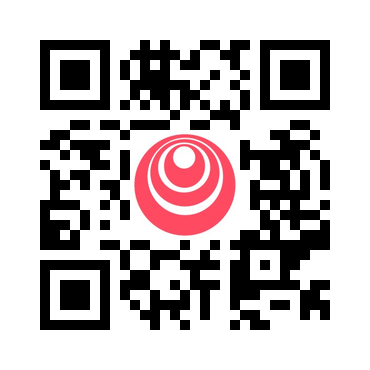

In [17]:
from IPython.display import Image, display

# Display image directly
Image('dl_qr_code.png')

### 4.3 同時使用多個工具

最後需要記住的是，LLM 可以按序列使用多個工具來完成多項任務。我們使用這些工具並檢視 `response`，觀察發生了什麼。你將使用一個較複雜的提示：

> 你能幫我用圖片 dl_logo.jpg 生成一個跳轉到 www.deeplearning.com 的二維碼嗎？另外請寫一個包含當前天氣的 txt 備忘。

該提示需要一定的邏輯來決定何時呼叫哪些工具。例如，儘管你讓它先寫文字備忘並隨後描述其內容，但 LLM 需要先獲取天氣資訊才能寫入備忘。如果它先呼叫 `write_txt_file`，則還沒有來自 `get_weather_from_ip` 的資訊。這個例子很好地展示了 LLM 解析自然語言並按正確順序使用合適工具以完成多樣任務的能力。

<div style="background-color: #ffe4e1; padding: 12px; border-radius: 6px; color: black;">

<h4>🔍 注意要點：</h4>

<ul>
  <li>LLM 會根據使用者請求<b>自動選擇</b>合適的工具</li>
  <li>從使用者訊息中<b>自動推斷引數</b>（如檔名、內容、URL）</li>
  <li>每個工具<b>返回資訊</b>並被 LLM 納入其最終響應</li>
  <li><b>無引數工具</b>（如天氣與時間）非常適合快速資訊查詢</li>
  <li>儘管幕後有複雜操作，對話依然<b>自然</b></li>
</ul>

</div>

In [18]:
prompt = "能否幫我用圖片 dl_logo.jpg 生成一個跳轉到 www.deeplearning.com 的二維碼？另外再寫一個包含當前天氣的 txt 備忘。"

response = client.chat.completions.create(
    model="openai:o4-mini",
    messages=[{"role": "user", "content": (
        prompt
    )}],
    tools=[
        get_weather_from_ip,
        get_current_time,
        write_txt_file,
        generate_qr_code
    ],
    max_turns=10
)

display_functions.pretty_print_chat_completion(response)

可以從工具呼叫序列中看到，智慧體按正確順序呼叫了工具以完成任務，同時以你要求的順序進行響應。

### 模型選項

在執行這些工具呼叫工作流時，你可以嘗試不同的 OpenAI 模型。不同模型在能力、成本與速度之間提供不同平衡：

- **`openai:gpt-4o`** — 最佳化了推理與速度
- **`openai:gpt-4.1`** — 強推理效能，適合複雜任務
- **`openai:gpt-4.1-mini`** — 比完整 GPT-4.1 更輕、更快、且更便宜
- **`openai:gpt-3.5-turbo`** — 適合更簡單任務與快速迭代

模型選擇取決於你的目標：
- 小模型適合快速、低成本的原型開發
- 當任務需要更強推理或多步編排時，切換到更強的模型


### 關鍵收穫

- 工具呼叫讓 LLM 超越純文字生成——它們可把函式作為推理的一部分。
- 清晰且文件完備的函式（精確的 docstring）有助於模型判斷何時、如何使用工具。
- AISuite 負責將 Python 函式轉換為工具 schema 並編排多步工作流的複雜性。
- 選擇合適模型很重要：小模型在簡單任務上更快更便宜，強模型更適合重推理的工作流。
- 觀察完整的會話流程（提示、工具呼叫、結果、最終響應）對於除錯與改進智慧體行為至關重要。

理解以上要素後，你已具備將 LLM 推理與外部工具結合以完成更複雜任務的基礎。


<div style="border:1px solid #22c55e; border-left:6px solid #16a34a; background:#dcfce7; border-radius:6px; padding:14px 16px; color:#064e3b; font-family:system-ui,-apple-system,Segoe UI,Roboto,Ubuntu,Cantarell,Noto Sans,sans-serif;">

🎉 <strong>恭喜！</strong>

你已經完成了使用 AISuite 將**函式變成工具**的範例。
在此過程中，<strong>你</strong>將 Python 函式暴露為工具，允許 LLM 選擇並呼叫它們，並檢查了多步工具編排。

具備這些技能後，<strong>你</strong>可以設計將 LLM 推理與實際動作結合的智慧體工作流——可靠、可審計且易擴充套件。🌟

</div>
